First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape:
(5572, 2)

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64

Training samples: 4457
Testing samples: 1115

Number of text features: 7668

--- Multinomial Naive Bayes ---
Accuracy: 98.74 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99    

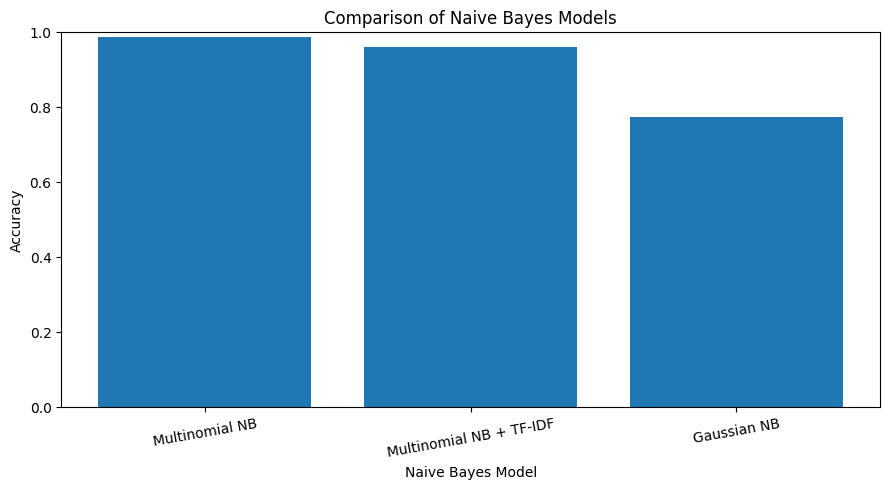


RESULT:
SMS messages were classified as Ham or Spam.
Different Naive Bayes approaches were compared.


In [1]:

# =========================================================
# MACHINE LEARNING - CO2
# PROGRAM 7: NAIVE BAYES CLASSIFICATION
# Dataset: SMSSpamCollection
# Platform: Google Colab
# =========================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# =========================================================
# 2. Load the dataset
# =========================================================

df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

# =========================================================
# 3. Prepare the data
# =========================================================

# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"])

# Convert labels into numbers
# Ham = 0, Spam = 1
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

# Separate input and output
X = df["message"]
y = df["label_num"]

# =========================================================
# 4. Split into training and testing data
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# =========================================================
# 5. Convert text into word counts
# =========================================================

vectorizer = CountVectorizer()

X_train_count = vectorizer.fit_transform(X_train)
X_test_count = vectorizer.transform(X_test)

print("\nNumber of text features:", X_train_count.shape[1])

# =========================================================
# 6. Multinomial Naive Bayes
# =========================================================

mnb_model = MultinomialNB()

mnb_model.fit(X_train_count, y_train)

mnb_pred = mnb_model.predict(X_test_count)

mnb_accuracy = accuracy_score(y_test, mnb_pred)

print("\n--- Multinomial Naive Bayes ---")
print("Accuracy:", round(mnb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    mnb_pred,
    target_names=["Ham", "Spam"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, mnb_pred))

# =========================================================
# 7. Test new SMS messages
# =========================================================

messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting tomorrow?",
    "URGENT! You have won a cash reward.",
    "Can you send me the notes?"
]

message_features = vectorizer.transform(messages)
predictions = mnb_model.predict(message_features)

print("\n--- New SMS Predictions ---")

for message, prediction in zip(messages, predictions):
    result = "SPAM" if prediction == 1 else "HAM"
    print("\nMessage:", message)
    print("Prediction:", result)

# =========================================================
# 8. Multinomial Naive Bayes using TF-IDF
# =========================================================

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

tfidf_model = MultinomialNB()

tfidf_model.fit(X_train_tfidf, y_train)

tfidf_pred = tfidf_model.predict(X_test_tfidf)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)

print("\n--- Multinomial Naive Bayes with TF-IDF ---")
print("Accuracy:", round(tfidf_accuracy * 100, 2), "%")

# =========================================================
# 9. Gaussian Naive Bayes
# =========================================================

# GaussianNB requires dense numerical arrays.
# Limit the vocabulary to control memory usage.

small_vectorizer = CountVectorizer(max_features=1000)

X_train_small = small_vectorizer.fit_transform(X_train)
X_test_small = small_vectorizer.transform(X_test)

gaussian_model = GaussianNB()

gaussian_model.fit(
    X_train_small.toarray(),
    y_train
)

gaussian_pred = gaussian_model.predict(
    X_test_small.toarray()
)

gaussian_accuracy = accuracy_score(
    y_test,
    gaussian_pred
)

print("\n--- Gaussian Naive Bayes ---")
print("Accuracy:", round(gaussian_accuracy * 100, 2), "%")

# =========================================================
# 10. Compare the models
# =========================================================

models = [
    "Multinomial NB",
    "Multinomial NB + TF-IDF",
    "Gaussian NB"
]

accuracies = [
    mnb_accuracy,
    tfidf_accuracy,
    gaussian_accuracy
]

print("\n--- Model Comparison ---")

for name, acc in zip(models, accuracies):
    print(name, ":", round(acc * 100, 2), "%")

# =========================================================
# 11. Plot accuracy comparison
# =========================================================

plt.figure(figsize=(9, 5))

plt.bar(models, accuracies)

plt.xlabel("Naive Bayes Model")
plt.ylabel("Accuracy")
plt.title("Comparison of Naive Bayes Models")
plt.ylim(0, 1)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# =========================================================
# 12. Result
# =========================================================

print("\nRESULT:")
print("SMS messages were classified as Ham or Spam.")
print("Different Naive Bayes approaches were compared.")
